# 04 — Ridge Model

**Goal:** tune a Ridge regression with **5-fold cross-validation**, choosing the penalty strength α that gives the **smallest mean absolute error (MAE)**, then predict wins for `predict.csv`.

MAE = average |actual wins − predicted wins|, so it reads directly as "off by this many wins on average".

Steps:
1. Load engineered data and the `regularized` preprocessor
2. Grid search α (5-fold CV, scored by MAE)
3. Check the result (α curve, nested CV, leave-decade-out)
4. Out-of-fold diagnostics (residuals, rounding)
5. Coefficients
6. Fit on all training data and write the submission

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV, cross_val_score, cross_validate, cross_val_predict
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

sns.set_theme(style='whitegrid')

# works whether the kernel starts in notebooks/, Model-3-Project/ or DSAI/
DATA_DIR = next(p for p in [Path('../Data'), Path('Data'), Path('Model-3-Project/Data')]
                if (p / 'train_features.csv').exists())
ARTIFACT_DIR = DATA_DIR.parent / 'artifacts'
SUBMISSION_DIR = DATA_DIR.parent / 'submissions'
SUBMISSION_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / 'train_features.csv')
pred = pd.read_csv(DATA_DIR / 'predict_features.csv')
config = json.loads((ARTIFACT_DIR / 'feature_config.json').read_text())
preprocessors = joblib.load(ARTIFACT_DIR / 'preprocessors.joblib')   # unfitted

FEATURES, TARGET, ID_COL = config['features'], config['target'], config['id_col']
X, y = train[FEATURES], train[TARGET]
print(f'train: {X.shape} | predict: {pred.shape} | features: {len(FEATURES)}')

train: (1412, 70) | predict: (400, 73) | features: 70


## 1. Grid search α
The pipeline (scaling → Ridge) is refit inside every fold, so the scaler only sees that fold's training rows. `GridSearchCV` scores each α by MAE and refits the best one on all the training data. RMSE is tracked alongside for reference.

In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pipe = Pipeline([('prep', preprocessors['regularized']), ('model', Ridge())])
param_grid = {'model__alpha': np.logspace(-3, 3, 61)}

search = GridSearchCV(
    pipe, param_grid, cv=cv,
    scoring={'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'},
    refit='MAE', n_jobs=-1,
)
search.fit(X, y)

best_alpha = search.best_params_['model__alpha']
i = search.best_index_
cvr = search.cv_results_
print(f'best alpha: {best_alpha:.4g}')
print(f"CV MAE : {-cvr['mean_test_MAE'][i]:.3f} ± {cvr['std_test_MAE'][i]:.3f} wins")
print(f"CV RMSE: {-cvr['mean_test_RMSE'][i]:.3f} ± {cvr['std_test_RMSE'][i]:.3f} wins")
print(f"CV R²  : {cvr['mean_test_R2'][i]:.3f} ± {cvr['std_test_R2'][i]:.3f}")
assert param_grid['model__alpha'].min() < best_alpha < param_grid['model__alpha'].max(), 'best alpha on grid edge: widen the grid'

best alpha: 2.512
CV MAE : 2.707 ± 0.064 wins
CV RMSE: 3.410 ± 0.063 wins
CV R²  : 0.934 ± 0.002


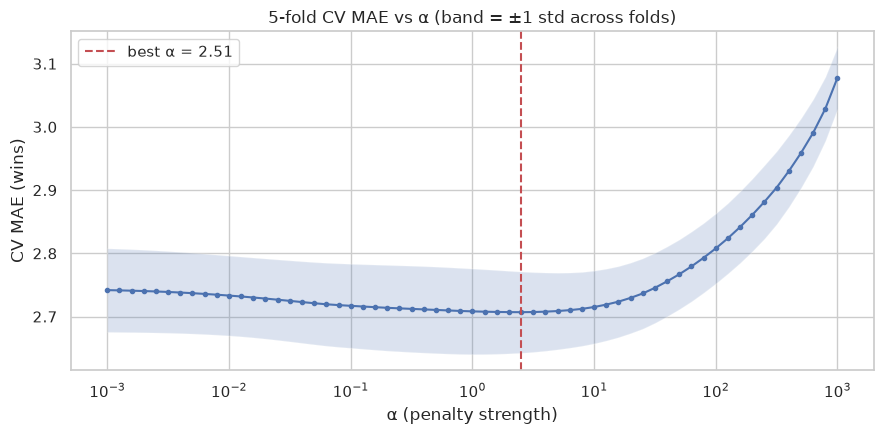

In [3]:
alphas = param_grid['model__alpha']
mae_mean, mae_std = -cvr['mean_test_MAE'], cvr['std_test_MAE']

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(alphas, mae_mean, marker='o', ms=3)
ax.fill_between(alphas, mae_mean - mae_std, mae_mean + mae_std, alpha=0.2)
ax.axvline(best_alpha, color='C3', ls='--', label=f'best α = {best_alpha:.3g}')
ax.set_xscale('log'); ax.set_xlabel('α (penalty strength)'); ax.set_ylabel('CV MAE (wins)')
ax.set_title('5-fold CV MAE vs α (band = ±1 std across folds)'); ax.legend()
plt.tight_layout()

Small α ≈ plain linear regression; large α shrinks every coefficient toward zero and underfits. The best α sits between them. The curve is fairly flat near the minimum, so the exact α matters little.

## 2. How trustworthy is that score?
- **Nested CV:** the score above picked α using the same folds it's measured on, which is slightly optimistic. Nested CV tunes α inside each outer fold and scores on data the tuning never saw.
- **Leave-decade-out:** trains on all other decades and tests on the held-out one, the competition's cross-era goal.

In [4]:
inner = GridSearchCV(clone(pipe), param_grid, cv=KFold(5, shuffle=True, random_state=0),
                     scoring='neg_mean_absolute_error', n_jobs=-1)
scoring = {'MAE': 'neg_mean_absolute_error', 'R2': 'r2'}
nested = cross_validate(inner, X, y, cv=cv, scoring=scoring)

best_pipe = search.best_estimator_
decade_cv = GroupKFold(n_splits=train['decade_label'].nunique())
decade = cross_validate(clone(best_pipe), X, y, cv=decade_cv, groups=train['decade_label'],
                        scoring=scoring)

pd.DataFrame({
    'MAE (wins)': [-cvr['mean_test_MAE'][i], -nested['test_MAE'].mean(), -decade['test_MAE'].mean()],
    'MAE ± std': [cvr['std_test_MAE'][i], nested['test_MAE'].std(), decade['test_MAE'].std()],
    'R²': [cvr['mean_test_R2'][i], nested['test_R2'].mean(), decade['test_R2'].mean()],
    'R² ± std': [cvr['std_test_R2'][i], nested['test_R2'].std(), decade['test_R2'].std()],
}, index=['5-fold (α tuned on same folds)', 'nested 5-fold', 'leave-decade-out']).round(3)

,MAE (wins),MAE ± std,R²,R² ± std
5-fold (α tuned on same folds),2.707,0.064,0.934,0.002
nested 5-fold,2.710,0.063,0.934,0.002
leave-decade-out,3.027,0.646,0.925,0.010


## 3. Out-of-fold diagnostics

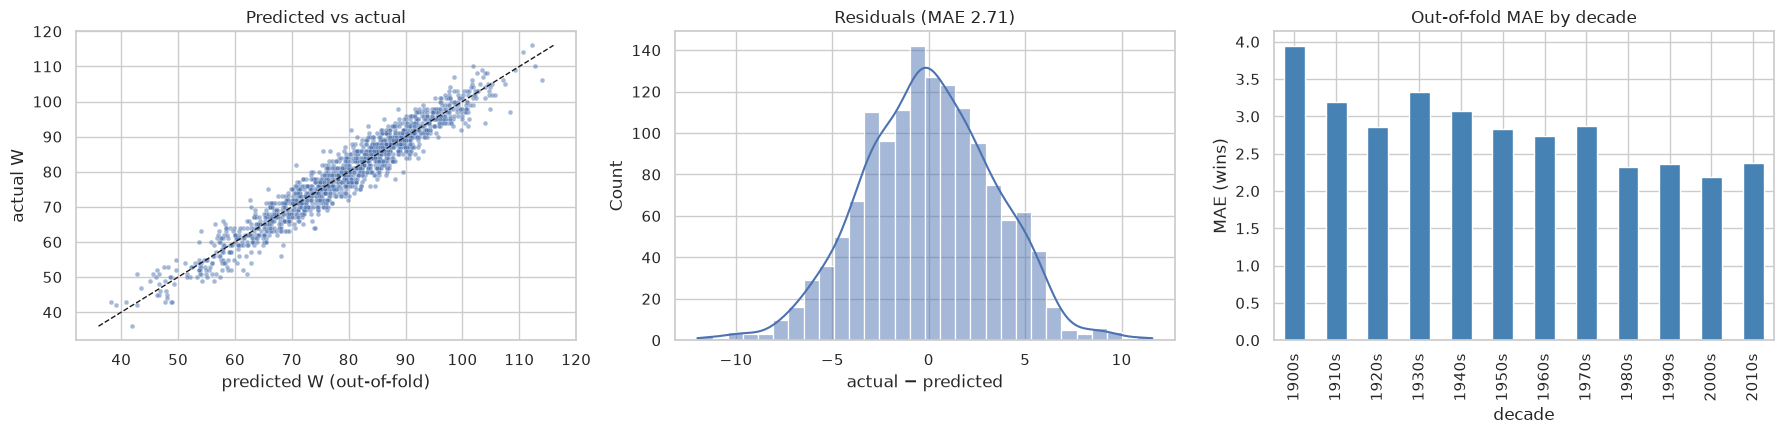

In [5]:
oof = cross_val_predict(clone(best_pipe), X, y, cv=cv)
resid = y - oof

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(x=oof, y=y, s=12, alpha=0.5, ax=axes[0])
lims = [y.min(), y.max()]; axes[0].plot(lims, lims, 'k--', lw=1)
axes[0].set(xlabel='predicted W (out-of-fold)', ylabel='actual W', title='Predicted vs actual')

sns.histplot(resid, bins=30, kde=True, ax=axes[1])
axes[1].set(xlabel='actual − predicted', title=f'Residuals (MAE {np.abs(resid).mean():.2f})')

by_decade = (pd.DataFrame({'decade': train['decade_label'], 'abs_err': resid.abs()})
             .groupby('decade')['abs_err'].mean())
by_decade.plot.bar(ax=axes[2], color='steelblue')
axes[2].set(ylabel='MAE (wins)', title='Out-of-fold MAE by decade')
plt.tight_layout()

### Should predictions be rounded?
Actual wins are whole numbers. Check whether rounding the predictions lowers MAE on the out-of-fold predictions:

In [6]:
mae_raw = mean_absolute_error(y, oof)
mae_round = mean_absolute_error(y, np.round(oof))
print(f'MAE raw: {mae_raw:.4f} | rounded: {mae_round:.4f}')
ROUND = mae_round < mae_raw
print('Rounding predictions' if ROUND else 'Keeping raw predictions')

MAE raw: 2.7070 | rounded: 2.7096
Keeping raw predictions


## 4. Coefficients
The numeric features are standardized, so each coefficient is the change in wins for a **one-standard-deviation** increase. Many features overlap (e.g. `pythpat_W`, `RD`, `log_R_RA`), and Ridge splits the weight between them, so read groups rather than single values.

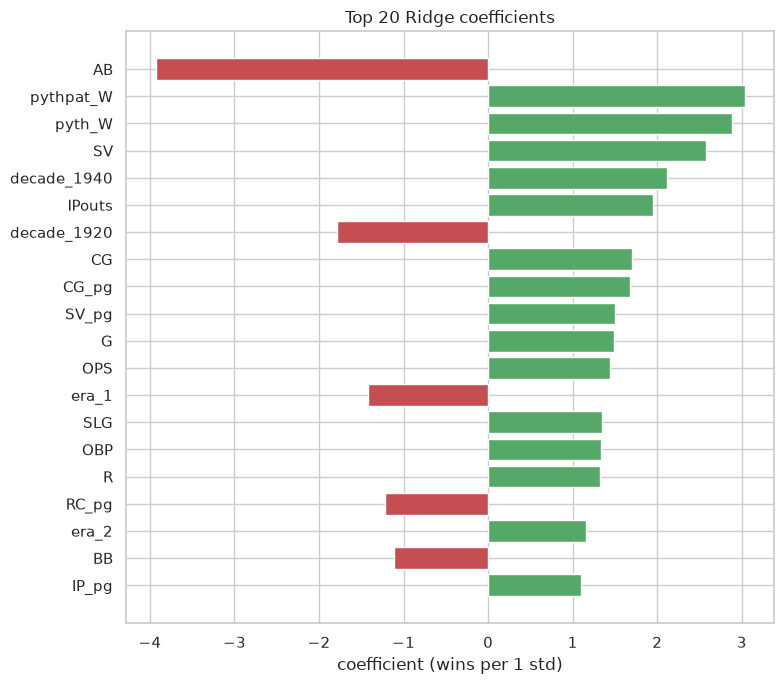

In [7]:
prep, model = best_pipe.named_steps['prep'], best_pipe.named_steps['model']
coefs = pd.Series(model.coef_, index=prep.get_feature_names_out()).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
top = coefs.head(20)
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, 'C2', 'C3'))
ax.set_xlabel('coefficient (wins per 1 std)'); ax.set_title('Top 20 Ridge coefficients')
plt.tight_layout()

## 5. Fit on all training data and predict

In [8]:
final = search.best_estimator_            # already refit on all training rows with the best α
pred_W = final.predict(pred[FEATURES])
pred_W = np.clip(pred_W, 0, pred['G'])    # wins can't be negative or exceed games played
if ROUND:
    pred_W = np.round(pred_W).astype(int)

submission = pd.DataFrame({ID_COL: pred[ID_COL], TARGET: pred_W})
print(submission[TARGET].describe().round(2))

count    400.00
mean      79.45
std       12.30
min       44.85
25%       69.86
50%       80.60
75%       88.75
max      113.15
Name: W, dtype: float64


In [9]:
# match the sample submission's format and row order
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
submission = sample[[ID_COL]].merge(submission, on=ID_COL, how='left', validate='one_to_one')
assert len(submission) == len(sample) and submission[TARGET].notna().all()

out_path = SUBMISSION_DIR / 'ridge_submission.csv'
submission.to_csv(out_path, index=False)
joblib.dump(final, ARTIFACT_DIR / 'ridge_model.joblib')
print('Saved:', out_path, '|', ARTIFACT_DIR / 'ridge_model.joblib')
submission.head()

Saved: ../submissions/ridge_submission.csv | ../artifacts/ridge_model.joblib


,ID,W
0,1649,76.757271
1,1223,76.513788
2,748,82.385708
3,1735,84.875181
4,794,78.752030


## Summary
See the outputs above for the tuned α and scores. Possible next steps:
- **Feature selection:** try the compact set (`pythpat_W` + close-game + flags) under the same search.
- **MAE-native models:** Ridge minimizes squared error; `HuberRegressor` or a median `QuantileRegressor` optimize closer to MAE directly.
- **Compare** with Lasso / ElasticNet and gradient boosting on the same folds.